<a href="https://colab.research.google.com/github/shirohigexe/practicas_HO_ML/blob/main/Final_Project_Canny.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importación de librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
import os
import gc
import cv2
from google.colab import drive
from random import randint
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Semilla para la partición reproducible de los datos
SEED = 42

In [ ]:
# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Definir la ruta
base_dir = '/content/drive/MyDrive/Opt&IA/Final/task8/'

# 3. Cargar los datos PHI-Net desde los archivos .npy
x_train_full = np.load(os.path.join(base_dir, 'task8_X_train.npy'))
y_train_full = np.load(os.path.join(base_dir, 'task8_y_train.npy'))
x_test_full = np.load(os.path.join(base_dir, 'task8_X_test.npy'))
y_test = np.load(os.path.join(base_dir, 'task8_y_test.npy'))

print(f"Imágenes originales de entrenamiento: {x_train_full.shape}")
print(f"Imágenes originales de prueba: {x_test_full.shape}")

Mounted at /content/drive
Imágenes originales de entrenamiento: (4093, 224, 224, 3)
Imágenes originales de prueba: (492, 224, 224, 3)


In [ ]:
# 4. División estratificada y preprocesamiento Canny
from sklearn.model_selection import train_test_split

# La estratificación utiliza la clase entera cuando las etiquetas están en one-hot.
stratify_labels = (np.argmax(y_train_full, axis=1)
                   if y_train_full.ndim > 1 and y_train_full.shape[1] > 1
                   else np.asarray(y_train_full).reshape(-1))
train_indices, valid_indices = train_test_split(
    np.arange(len(x_train_full)),
    test_size=0.2,
    random_state=SEED,
    stratify=stratify_labels
)


def _to_uint8_rgb(image):
    """Convierte una imagen RGB a uint8 de forma robusta para OpenCV.

    Admite imágenes en [0, 255], [0, 1] y datos centrados/normalizados con
    valores negativos. Para estos últimos escala por percentiles por imagen.
    """
    image = np.asarray(image)

    if image.ndim == 2:
        image = np.repeat(image[..., None], 3, axis=-1)
    elif image.ndim == 3 and image.shape[-1] == 1:
        image = np.repeat(image, 3, axis=-1)
    elif image.ndim == 3 and image.shape[-1] > 3:
        image = image[..., :3]

    if image.dtype == np.uint8:
        return np.ascontiguousarray(image)

    image = image.astype(np.float32, copy=False)
    image = np.nan_to_num(image, nan=0.0, posinf=0.0, neginf=0.0)
    min_value = float(image.min())
    max_value = float(image.max())

    if min_value >= 0.0 and max_value <= 1.0:
        image = image * 255.0
    elif min_value >= 0.0 and max_value <= 255.0:
        pass  # Ya está en escala de 8 bits; solo falta convertir el tipo.
    elif max_value > min_value:
        # Para entradas normalizadas o centradas (p. ej. con valores negativos).
        low, high = np.percentile(image, (1, 99))
        if high <= low:
            low, high = min_value, max_value
        if high > low:
            image = (image - low) / (high - low) * 255.0
        else:
            image = np.zeros_like(image)
    else:
        image = np.zeros_like(image)

    return np.ascontiguousarray(np.clip(image, 0, 255).astype(np.uint8))


def canny_edges_rgb(image, threshold1=50, threshold2=150):
    """Devuelve un mapa Canny RGB (224x224x3) con valores compactos 0/1."""
    rgb = _to_uint8_rgb(image)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    edges = cv2.Canny(gray, threshold1, threshold2, L2gradient=True)
    # Guardar los bordes en {0,1} reduce 8 veces la memoria frente a float32.
    edges = (edges > 0).astype(np.uint8)
    # Se replican los bordes en los tres canales para conservar la entrada del MLP.
    return np.repeat(edges[..., None], 3, axis=-1)


def canny_batch(images, indices, name):
    """Procesa una vez cada imagen con OpenCV y devuelve un array uint8 compacto."""
    height, width = images.shape[1:3]
    result = np.empty((len(indices), height, width, 3), dtype=np.uint8)
    for output_index, image_index in enumerate(indices):
        result[output_index] = canny_edges_rgb(images[int(image_index)])
        if (output_index + 1) % 500 == 0 or output_index + 1 == len(indices):
            print(f"{name}: {output_index + 1}/{len(indices)} imágenes procesadas")
    return result


# Canny se calcula solo una vez y sus salidas se reutilizan tanto en el modelo
# principal como en la búsqueda de hiperparámetros.
x_train = canny_batch(x_train_full, train_indices, "Entrenamiento")
x_valid = canny_batch(x_train_full, valid_indices, "Validación")
x_test = canny_batch(x_test_full, np.arange(len(x_test_full)), "Prueba")

y_train = y_train_full[train_indices]
y_valid = y_train_full[valid_indices]

# Liberar las imágenes originales para reducir el pico de uso de memoria.
del x_train_full, x_test_full, y_train_full, stratify_labels, train_indices, valid_indices
gc.collect()

# El MLP sigue recibiendo tensores de 224x224x3; los píxeles Canny ya están
# normalizados a 0/1, por lo que no se vuelven a dividir entre 255.
class_names = ["Undamaged", "Flexural", "Shear", "Combined"]
print(f"Dimensiones Canny entrenamiento: {x_train.shape} ({x_train.dtype})")
print(f"Dimensiones Canny validación: {x_valid.shape} ({x_valid.dtype})")
print(f"Dimensiones Canny prueba: {x_test.shape} ({x_test.dtype})")

Entrenamiento: 500/3274 imágenes procesadas
Entrenamiento: 1000/3274 imágenes procesadas
Entrenamiento: 1500/3274 imágenes procesadas
Entrenamiento: 2000/3274 imágenes procesadas
Entrenamiento: 2500/3274 imágenes procesadas
Entrenamiento: 3000/3274 imágenes procesadas
Entrenamiento: 3274/3274 imágenes procesadas
Validación: 500/819 imágenes procesadas
Validación: 819/819 imágenes procesadas
Prueba: 492/492 imágenes procesadas
Dimensiones Canny entrenamiento: (3274, 224, 224, 3) (uint8)
Dimensiones Canny validación: (819, 224, 224, 3) (uint8)
Dimensiones Canny prueba: (492, 224, 224, 3) (uint8)


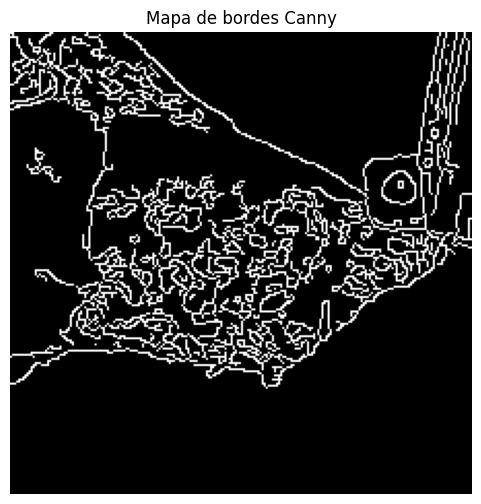

In [ ]:
# Visualización de una muestra después de aplicar Canny
sample_index = randint(0, len(x_train) - 1)
plt.figure(figsize=(6, 6))
plt.imshow(x_train[sample_index] * 255, cmap="gray")
plt.title("Mapa de bordes Canny")
plt.axis("off")
plt.show()

In [ ]:
#Generación del modelo
model_Adam = keras.models.Sequential([
    keras.layers.Flatten(input_shape=[224, 224, 3]),

    # Capas ocultas densas con sus unidades correspondientes
    keras.layers.Dense(512, activation="relu"),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(512, activation="relu"),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(512, activation="relu"),
    keras.layers.BatchNormalization(),
    keras.layers.Dropout(0.3),


    keras.layers.Dense(4, activation="softmax")
])

model_Adam.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    77,070,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 77,604,356 (296.04 MB)

 Trainable params: 77,601,284 (296.03 MB)

 Non-trainable params: 3,072 (12.00 KB)

In [ ]:
# 1. Re-compilar el modelo usando 'categorical_crossentropy' para etiquetas One-Hot
optim = keras.optimizers.Adam(learning_rate=3e-3)
model_Adam.compile(loss="categorical_crossentropy",
              optimizer=optim,
              metrics=["accuracy"])

# 2. Entrenar usando el conjunto de validación correcto (x_valid, y_valid)
history = model_Adam.fit(x_train, y_train, epochs=30,
                    validation_data=(x_valid, y_valid))

Epoch 1/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 14s 74ms/step - accuracy: 0.3396 - loss: 1.7136 - val_accuracy: 0.4042 - val_loss: 1.5601
Epoch 2/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.4423 - loss: 1.3574 - val_accuracy: 0.3822 - val_loss: 1.4297
Epoch 3/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.6659 - loss: 0.9077 - val_accuracy: 0.3773 - val_loss: 1.4858
Epoch 4/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8305 - loss: 0.5016 - val_accuracy: 0.3333 - val_loss: 2.1355
Epoch 5/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.8937 - loss: 0.3284 - val_accuracy: 0.4261 - val_loss: 2.6242
Epoch 6/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9304 - loss: 0.2055 - val_accuracy: 0.3871 - val_loss: 2.5398
Epoch 7/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9478 - loss: 0.1624 - val_accuracy: 0.4212 - val_loss: 2.5710
Epoch 8/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9566 - loss: 0.1398 - val_acc

In [ ]:
# 3. Evaluar el rendimiento final con el conjunto de prueba
model_Adam.evaluate(x_test, y_test)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.3943 - loss: 3.6444


[3.64437198638916, 0.3943089544773102]

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step


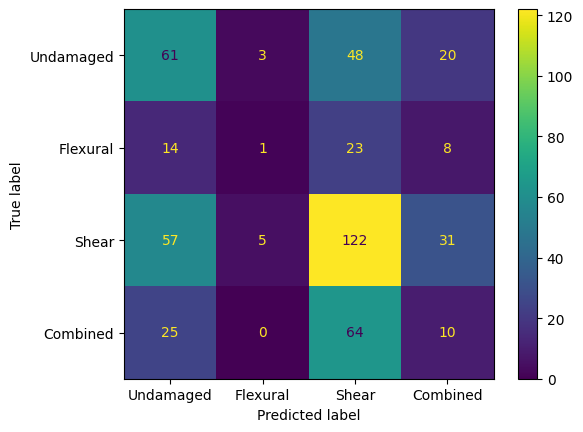

In [ ]:
# Predicción: corresponde a la probabilidad de pertenecer a cada clase
y_pred_prob = model_Adam.predict(x_test)

# Convertir probabilidades a clases (formato entero)
y_pred = np.argmax(y_pred_prob, axis=1)

# Convertir y_test de one-hot a clases (formato entero)
y_test_classes = np.argmax(y_test, axis=1)

# Cálculo de la matriz de confusión usando las dos variables en el mismo formato
cm_rf = confusion_matrix(y_test_classes, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=class_names)
disp.plot()

In [ ]:
%pip install -q keras-tuner --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.9 MB/s eta 0:00:00


In [ ]:
import keras_tuner as kt
from tensorflow import keras

# 1. Definir la función de construcción del modelo (HyperModel)
def build_model(hp):
    model = keras.Sequential()
    # Capa de entrada adaptada a tus imágenes de 224x224x3
    model.add(keras.layers.Flatten(input_shape=[224, 224, 3]))

    # Hiperparámetro A: Número de capas ocultas (entre 1 y 3)
    hp_layers = hp.Int('num_layers', min_value=1, max_value=3)

    for i in range(hp_layers):
        # Hiperparámetro B: Número de neuronas en cada capa (de 256 a 1024, en saltos de 256)
        hp_units = hp.Int(f'units_{i}', min_value=256, max_value=1024, step=256)
        model.add(keras.layers.Dense(units=hp_units, activation='relu'))
        # Opcional: BatchNormalization y Dropout para evitar el sobreajuste
        model.add(keras.layers.BatchNormalization())
        model.add(keras.layers.Dropout(0.3))

    # Capa de salida para 4 clases de daño estructural
    model.add(keras.layers.Dense(4, activation='softmax'))

    # Hiperparámetro C: Tasa de aprendizaje (Learning Rate)
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])

    # Compilación usando Adam
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_learning_rate),
        loss='categorical_crossentropy', # Cambiado a categorical por One-Hot
        metrics=['accuracy']
    )

    return model

# 2. Configurar el sintonizador (Tuner) de Búsqueda Aleatoria
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,        # Al menos 10 pruebas
    overwrite=True,       # Sobrescribir búsquedas previas fallidas
    directory='mlp_tuning',
    project_name='structural_damage_optimization'
)

# Mostrar resumen del espacio de búsqueda
tuner.search_space_summary()

# 3. Ejecutar la optimización
print("\nIniciando búsqueda de hiperparámetros...")
tuner.search(x_train, y_train, epochs=35, validation_data=(x_valid, y_valid))

# 4. Obtener los mejores hiperparámetros encontrados
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\n--- Resultados de la Optimización ---")
print(f"Mejor número de capas ocultas: {best_hps.get('num_layers')}")
print(f"Mejor tasa de aprendizaje: {best_hps.get('learning_rate')}")
# Imprimir neuronas por capa
for i in range(best_hps.get('num_layers')):
    print(f"Neuronas en la capa {i+1}: {best_hps.get(f'units_{i}')}")

# 5. Evaluación final del mejor modelo
print("\nReentrenando el mejor modelo para evaluación final...")
best_model = tuner.hypermodel.build(best_hps)
history_best = best_model.fit(x_train, y_train, epochs=35, validation_data=(x_valid, y_valid))

# Desempeño en los datos de prueba
test_loss, test_acc = best_model.evaluate(x_test, y_test)
print(f"\nPrecisión (Accuracy) final en prueba: {test_acc:.4f}")

Trial 1 Complete [00h 04m 29s]
val_accuracy: 0.41636142134666443

Best val_accuracy So Far: 0.41636142134666443
Total elapsed time: 00h 04m 29s

Search: Running Trial #2

Value             |Best Value So Far |Hyperparameter
2                 |1                 |num_layers
1024              |1024              |units_0
0.0001            |0.001             |learning_rate

Epoch 1/35
103/103 ━━━━━━━━━━━━━━━━━━━━ 34s 293ms/step - accuracy: 0.2914 - loss: 2.0374 - val_accuracy: 0.3932 - val_loss: 1.6065
Epoch 2/35
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7636 - loss: 0.6489 - val_accuracy: 0.3370 - val_loss: 1.5822
Epoch 3/35
103/103 ━━━━━━━━━━━━━━━━━━━━ 34s 318ms/step - accuracy: 0.8949 - loss: 0.3262 - val_accuracy: 0.4127 - val_loss: 1.8384
Epoch 4/35
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9456 - loss: 0.1973 - val_accuracy: 0.4078 - val_loss: 1.8750
Epoch 5/35
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.9664 - loss: 0.1489 - val_accuracy: 0.394